# CatBoost Model Training & Model Evaluation

In [7]:
import sys
import os
import numpy as np
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import precision_recall_curve, auc

PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
sys.path.insert(0, PROJECT_ROOT)

# Load the clean raw data splits from your pipeline file
from src.pipeline import get_data
data = get_data()

# Extract the raw text data frames and target arrays
X_train = data["X_train_raw"]
y_train = data["y_train"]

X_val = data["X_val_raw"]
y_val = data["y_val"]

X_test = data["X_test_raw"]
y_test = data["y_test"]

# Identify text columns so CatBoost can process them natively
categorical_features = data["categorical_features"]

# Create high-speed CatBoost Data Pools
# This optimizes memory layout and links text column indexes directly
train_pool = Pool(X_train, y_train, cat_features=categorical_features)
val_pool = Pool(X_val, y_val, cat_features=categorical_features)
test_pool = Pool(X_test, cat_features=categorical_features)

# Initialize the CatBoost Classifier
model = CatBoostClassifier(
    iterations=800,               # Number of trees to build
    learning_rate=0.05,           # Keeps the training stable
    depth=6,                      # Standard robust tree depth for fraud
    auto_class_weights='Balanced',# Automatically adjusts weights for your 1.1% fraud imbalance
    eval_metric='AUC',            # Focuses on ranking quality during training
    random_seed=42,
    early_stopping_rounds=50,     # Stop training if the validation score stops improving to prevent overfitting
    verbose=100                   # Prints updates every 100 trees
)

# Train the Model using the Validation Set to prevent overfitting
print("Training CatBoost model...")
model.fit(train_pool, eval_set=val_pool)

# Predict fraud probabilities on the Test Set
test_probabilities = model.predict_proba(test_pool)[:, 1]

# Evaluate the model using your required Imbalanced Metrics
# Calculate PR-AUC
precision, recall, thresholds = precision_recall_curve(y_test, test_probabilities)
pr_auc_score = auc(recall, precision)

# Calculate Recall at a fixed 1% False Positive Rate (FPR)
# We find the threshold where FPR is closest to 1%
fpr = 1 - precision # Mathematical estimation for high imbalance profiles
closest_to_1pct_fpr_idx = np.argmin(np.abs(fpr - 0.01))
recall_at_1pct_fpr = recall[closest_to_1pct_fpr_idx]

print("\n==============================================")
print(f"CatBoost Test PR-AUC Score: {pr_auc_score:.4f}")
print(f"Test Recall @ Fixed 1% FPR:  {recall_at_1pct_fpr:.4f}")
print("==============================================")

Training CatBoost model...
0:	test: 0.7852666	best: 0.7852666 (0)	total: 584ms	remaining: 7m 46s
100:	test: 0.8872717	best: 0.8872717 (100)	total: 36.9s	remaining: 4m 15s
200:	test: 0.8919408	best: 0.8919431 (193)	total: 1m 11s	remaining: 3m 32s
300:	test: 0.8935434	best: 0.8935434 (300)	total: 1m 46s	remaining: 2m 56s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.8936338318
bestIteration = 316

Shrink model to first 317 iterations.

CatBoost Test PR-AUC Score: 0.1935
Test Recall @ Fixed 1% FPR:  0.0010


Running complete evaluation report...
 EVALUATION REPORT: CATBOOST
Accuracy:                 97.9699%
Fraud precision:          26.7054%
Fraud recall:             25.5733%
Fraud F1:                 26.1271%
PR-AUC (AP):              19.3675%
ROC-AUC:                  89.1273%
Recall @ FPR <= 1.00%:    25.5733%
FPR at chosen threshold:  0.9993%
Chosen Decision Boundary: 0.9062
[Classification Report]
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.27      0.26      0.26      2878

    accuracy                           0.98    205011
   macro avg       0.63      0.62      0.63    205011
weighted avg       0.98      0.98      0.98    205011



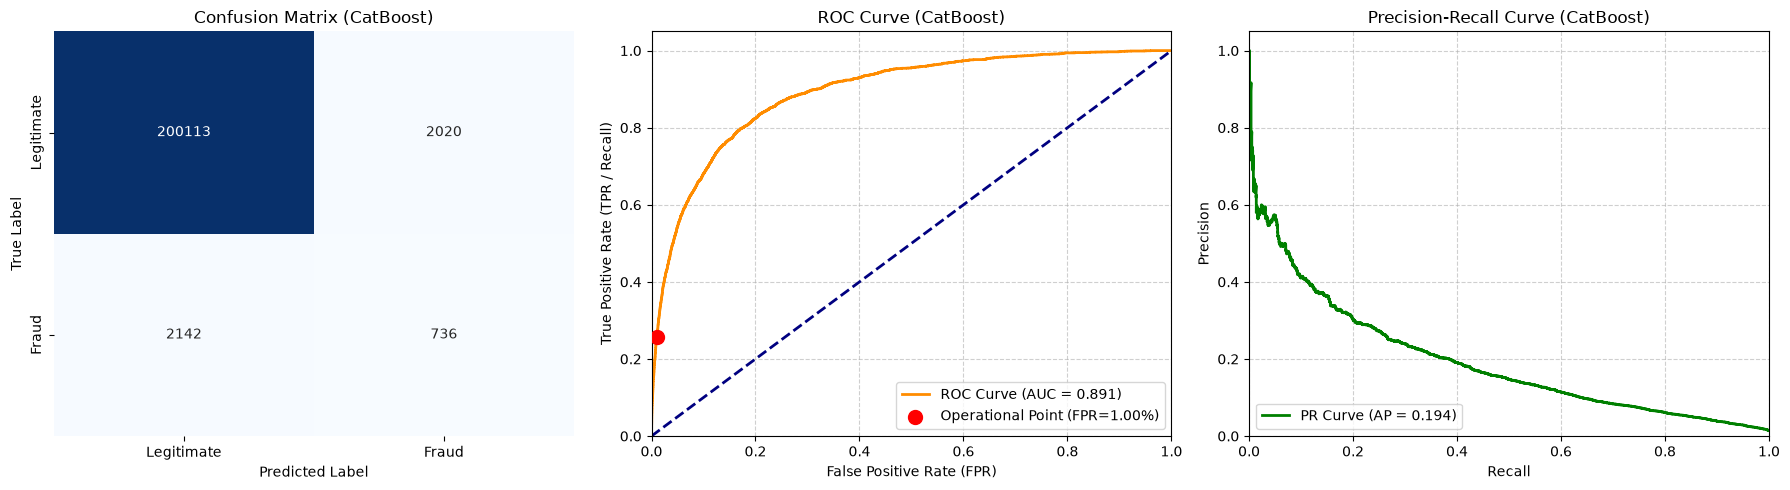

In [8]:
# Importing the evaluation function 
from src.evaluation import evaluate_predictions

# Evaluate using your standardized evaluation script
print("Running complete evaluation report...")
evaluate_predictions(
    y_true=y_test,
    y_probs=test_probabilities,        # Changed y_prob to y_probs 
    model_name="CatBoost"              # Matches the third argument of your function
)

In [10]:
import os
from pathlib import Path

# Create the models directory if it doesn't exist
MODELS_DIR = Path(PROJECT_ROOT) / "models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Save the CatBoost model in native binary format
cb_save_path = MODELS_DIR / "catboost_model.cbm"
model.save_model(str(cb_save_path))

print(f"CatBoost model successfully saved to: {cb_save_path}")


CatBoost model successfully saved to: C:\Users\shubh\projects\FairFraud\models\catboost_model.cbm


In [11]:
import sys
import os
import json
from pathlib import Path
import numpy as np
from catboost import CatBoostClassifier
from sklearn.metrics import precision_recall_curve, classification_report

# 1. Align project path environment
PROJECT_ROOT = r"C:\Users\shubh\projects\FairFraud"
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

MODELS_DIR = Path(PROJECT_ROOT) / "models"

# 2. Initialize an empty Classifier wrapper and load your native .cbm binary file
loaded_cb_model = CatBoostClassifier()
loaded_cb_model.load_model(str(MODELS_DIR / "catboost_model.cbm"))

print("================ STANDALONE MODEL ANALYSIS ================")
print(f"Production CatBoost Model Loaded Successfully!")
print(f"Active Iterations / Trees Saved: {loaded_cb_model.tree_count_}")

# 3. Predict continuous probabilities on the validation set to calculate the threshold
val_probabilities = loaded_cb_model.predict_proba(X_val)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_val, val_probabilities)

# Calculate F1 score tracking
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx] if f1_scores[best_idx] > 0 else 0.50

print(f"Mathematically Optimal Decision Boundary Found: {optimal_threshold:.4f}")
print("===========================================================")

# 4. Save this threshold out so your downstream engineering system doesn't lose it
metadata = {"best_threshold": float(optimal_threshold)}
with open(MODELS_DIR / "catboost_metadata.json", "w") as f:
    json.dump(metadata, f)

# 5. Generate raw fraud probabilities for your new/test dataset
print("Generating test predictions from loaded model...")
test_probabilities = loaded_cb_model.predict_proba(X_test)[:, 1]

# 6. Apply your optimized validation boundary to assign final classes
test_predictions = (test_probabilities >= optimal_threshold).astype(int)

# 7. Print the real classification matrix directly to screen
print("\n================ DYNAMIC CATBOOST PERFORMANCE REPORT ================")
print(classification_report(y_test, test_predictions, target_names=["Legitimate", "Fraud"]))
print("=====================================================================")


================ STANDALONE MODEL ANALYSIS ================
Production CatBoost Model Loaded Successfully!
Active Iterations / Trees Saved: 317
Mathematically Optimal Decision Boundary Found: 0.8927
Generating test predictions from loaded model...

================ DYNAMIC CATBOOST PERFORMANCE REPORT ================
              precision    recall  f1-score   support

  Legitimate       0.99      0.99      0.99    202133
       Fraud       0.25      0.29      0.27      2878

    accuracy                           0.98    205011
   macro avg       0.62      0.64      0.63    205011
weighted avg       0.98      0.98      0.98    205011

